In [12]:
import numpy as np
from scipy.fft import dct, idct
import matplotlib.pyplot as plt

In [13]:
f = open("Wildlife.wmv", "rb")

In [14]:
from struct import unpack

fr = f.read(((0x100**2)))
f.close()
l = unpack("<" + "b" * len(fr), fr)
len(fr)

65536

In [15]:
coef = np.round(dct(l, norm="ortho")).astype(np.int64)
threshold = np.sqrt(abs(coef).max())
scoef = np.sort(coef)
coeft = np.array([i if abs(i) > threshold else 0 for i in coef])
reconstructed = np.round(idct(coeft, norm="ortho")).astype(np.int64)
((l != reconstructed)).sum()

np.int64(63481)

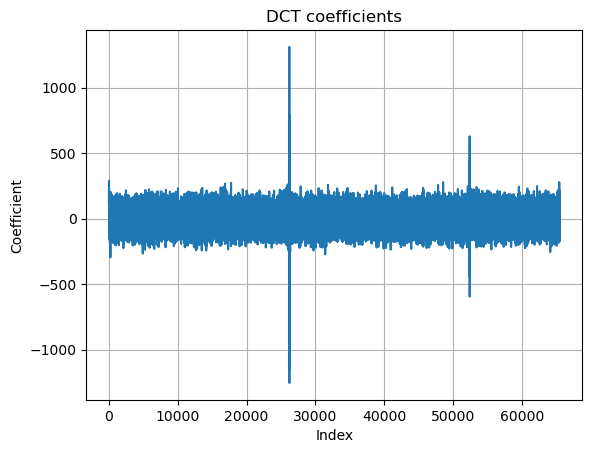

In [16]:
plt.plot(coef)
plt.xlabel("Index")
plt.ylabel("Coefficient")
plt.title("DCT coefficients")
plt.grid(True)
plt.show()

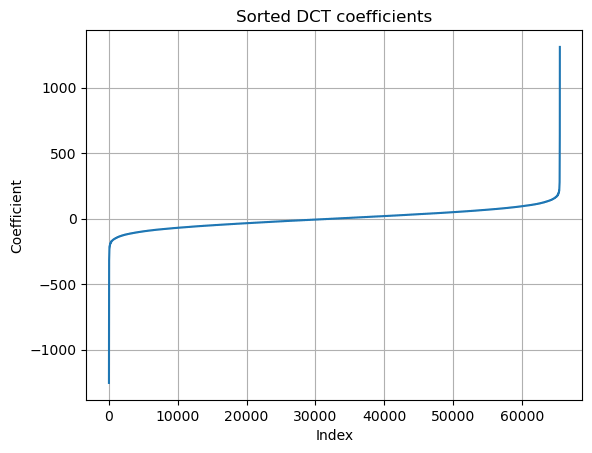

In [17]:
scoef = np.sort(coef)
plt.plot(scoef)
plt.xlabel("Index")
plt.ylabel("Coefficient")
plt.title("Sorted DCT coefficients")
plt.grid(True)
plt.show()

In [18]:
threshold

np.float64(36.207733980463345)

In [19]:
coeftn = coeft - coeft.min()
coeft.min()

np.int64(-1255)

In [20]:
energy = coef ** 2
sorted_energy = np.sort(energy)[::-1]
total = energy.sum()

for percent in [1, 5, 10, 25, 50]:
    k = max(1, int(len(coef) * percent / 100))
    ratio = sorted_energy[:k].sum() / total

    print(f"Top {percent:2d}%: {ratio:.2%} energy")

Top  1%: 15.21% energy
Top  5%: 33.42% energy
Top 10%: 48.23% energy
Top 25%: 74.37% energy
Top 50%: 93.34% energy


In [21]:
print(np.sum(np.array(l).astype(float)**2))
print(np.sum(coef**2))

332961352.0
332970144


In [22]:
import heapq

def huffman_bits(data):
    _, counts = np.unique(data, return_counts=True)
    heap = counts.astype(int).tolist()

    if len(heap) <= 1:
        return 0

    heapq.heapify(heap)
    bits = 0

    while len(heap) > 1:
        a = heapq.heappop(heap)
        b = heapq.heappop(heap)
        bits += a + b
        heapq.heappush(heap, a + b)

    return bits


# 원본과 DCT 계수
x = np.asarray(l, dtype=np.int32)
c = np.rint(dct(x, norm="ortho")).astype(np.int32)

# 절댓값이 큰 순서로 정렬한 인덱스
order = np.argsort(np.abs(c))[::-1]

raw_bits = huffman_bits(x)

print("Raw Huffman:", (raw_bits + 7) // 8, "bytes")
print()
print("KEEP% | MODEL(B) | RESID(B) | TOTAL(B) | MAE")

for percent in [0, 1, 5, 10, 25, 50, 75, 100]:

    k = int(len(c) * percent / 100)

    # 가장 큰 k개 계수만 유지
    q = np.zeros_like(c)
    q[order[:k]] = c[order[:k]]

    # 역변환
    predicted = np.rint(
        idct(q.astype(float), norm="ortho")
    ).astype(np.int32)

    # 무손실 복원을 위한 차이
    residual = x - predicted

    # 계수 저장 비용:
    # 위치 2바이트 + 계수 int16 2바이트
    # 또는 위치 비트맵 + 계수 int16 중 작은 것
    nonzero = np.count_nonzero(q)

    model_bytes = min(
        nonzero * 4,
        (len(q) + 7) // 8 + nonzero * 2
    )

    residual_bytes = (huffman_bits(residual) + 7) // 8

    total = model_bytes + residual_bytes
    mae = np.mean(np.abs(residual))

    print(
        f"{percent:5d} | "
        f"{model_bytes:8d} | "
        f"{residual_bytes:8d} | "
        f"{total:8d} | "
        f"{mae:.3f}"
    )

Raw Huffman: 62514 bytes

KEEP% | MODEL(B) | RESID(B) | TOTAL(B) | MAE
    0 |        0 |    62514 |    62514 | 58.531
    1 |     2620 |    65926 |    68546 | 53.716
    5 |    13104 |    64982 |    78086 | 47.458
   10 |    21298 |    63461 |    84759 | 41.512
   25 |    40960 |    59450 |   100410 | 28.911
   50 |    73728 |    51509 |   125237 | 14.665
   75 |   106496 |    38686 |   145182 | 5.007
  100 |   138560 |     8885 |   147445 | 0.085
